In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

In [ ]:
df=pd.read_csv("covtype.csv")

In [ ]:
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [ ]:
print("Missing Values :")
df.isnull().sum()

Missing Values :


,0
Elevation,0
Aspect,0
Slope,0
Horizontal_Distance_To_Hydrology,0
Vertical_Distance_To_Hydrology,0
Horizontal_Distance_To_Roadways,0
Hillshade_9am,0
Hillshade_Noon,0
Hillshade_3pm,0
Horizontal_Distance_To_Fire_Points,0


In [ ]:
X=df.iloc[:, :-1]
y=df.iloc[:, -1]

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
scaler=StandardScaler()

In [ ]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [ ]:
model = RandomForestClassifier(random_state=42)
model.fit(X_train_scaled,y_train)

RandomForestClassifier(random_state=42)

In [ ]:

y_pred=model.predict(X_test_scaled)


In [ ]:

rf_accuracy = accuracy_score(y_test, y_pred)
rf_precision = precision_score(y_test, y_pred, average="weighted")
rf_recall = recall_score(y_test, y_pred, average="weighted")
rf_f1 = f1_score(y_test, y_pred, average="weighted")


In [ ]:
print("\nRandom Forest")
print("Accuracy :", rf_accuracy*100)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)



Random Forest
Accuracy : 95.51388518368717
Precision: 0.9552451773452774
Recall   : 0.9551388518368716
F1 Score : 0.9548963012046161


In [ ]:
results=pd.DataFrame({
    'Model':['Random Forest'],
    'Accuracy':[rf_accuracy],
    'Precision':[rf_precision],
    'Recall':[rf_recall],
    'F1 Score':[rf_f1]
})

In [ ]:
from sklearn.metrics import classification_report

print("Random Forest")
print(classification_report(y_test, y_pred))


Random Forest
              precision    recall  f1-score   support

           1       0.97      0.94      0.95     42557
           2       0.95      0.97      0.96     56500
           3       0.94      0.96      0.95      7121
           4       0.91      0.85      0.88       526
           5       0.94      0.77      0.85      1995
           6       0.94      0.90      0.92      3489
           7       0.97      0.96      0.96      4015

    accuracy                           0.96    116203
   macro avg       0.95      0.91      0.93    116203
weighted avg       0.96      0.96      0.95    116203



In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print("Random Forest Confusion Matrix:")
print(cm)

Random Forest Confusion Matrix:
[[40160  2299     0     0     9     2    87]
 [ 1237 55015    96     0    76    62    14]
 [    2    98  6867    23     6   125     0]
 [    0     0    66   445     0    15     0]
 [   28   401    17     0  1537    12     0]
 [    1   107   228    19     5  3129     0]
 [  153    25     0     0     0     0  3837]]


In [ ]:
df.shape

(581012, 55)

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

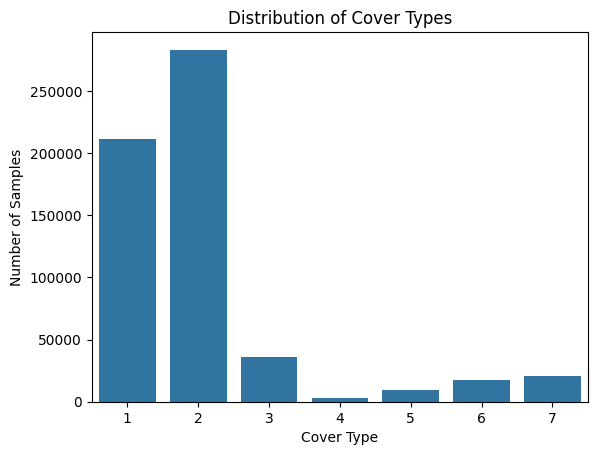

In [ ]:
sns.countplot(x="Cover_Type",data=df)
plt.title("Distribution of Cover Types")
plt.xlabel("Cover Type")
plt.ylabel("Number of Samples")
plt.show()

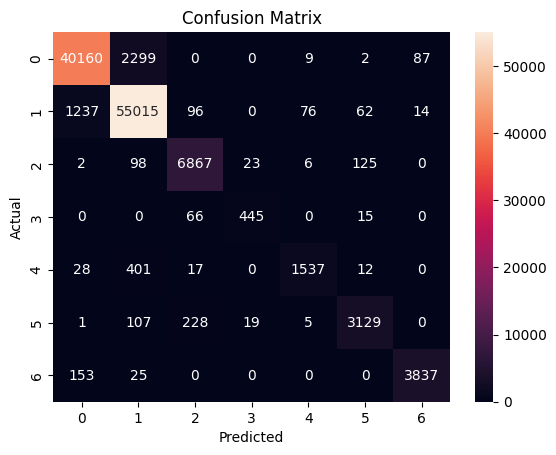

In [ ]:
sns.heatmap(cm,annot=True,fmt="d")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()